# Validação honesta: vazamento de dados, out of time e amostra pequena

**Objetivo:** mostrar, com experimentos controlados, quatro armadilhas que fazem um modelo parecer melhor do que é, e como evitá-las.

**Dados:** todos **sintéticos**, gerados no próprio notebook. Nenhum dado real é usado.

| # | Armadilha | O que acontece |
|---|---|---|
| 1 | Variável do futuro | o modelo usa uma informação que só existe depois do fato |
| 2 | Pré-processamento antes do split | o teste "vaza" para o treino pela seleção de variáveis |
| 3 | Split aleatório em dado temporal | o teste não representa o futuro |
| 4 | Amostra pequena | um 100% que não prova nada |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score
from statsmodels.stats.proportion import proportion_confint
rng = np.random.default_rng(0)
plt.rcParams['figure.figsize'] = (8, 3.5)

## 1. Variável do futuro

Cenário: prever se uma transação é fraude. A base tem a coluna `estorno_registrado`, preenchida **depois** que o cliente contesta. Ela está fortemente ligada ao alvo, mas não existe no momento da decisão.

In [2]:
n = 20_000
X = pd.DataFrame({'valor': rng.lognormal(4, 1, n), 'hora': rng.integers(0, 24, n),
                  'dispositivo_novo': rng.binomial(1, 0.06, n), 'distancia_km': rng.exponential(10, n)})
logit = -5 + 0.6 * np.log(X['valor']) + 1.5 * X['dispositivo_novo'] + 0.04 * X['distancia_km'] + 0.8 * (X['hora'] < 6) + rng.normal(0, 1, n)
y = rng.binomial(1, 1 / (1 + np.exp(-logit)))
X['estorno_registrado'] = np.where(y == 1, rng.binomial(1, 0.9, n), rng.binomial(1, 0.01, n))  # só existe depois

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
m = HistGradientBoostingClassifier(random_state=0)
auc_com = roc_auc_score(y_te, m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1])
cols = ['valor', 'hora', 'dispositivo_novo', 'distancia_km']
auc_sem = roc_auc_score(y_te, m.fit(X_tr[cols], y_tr).predict_proba(X_te[cols])[:, 1])
print(f"Taxa de fraude: {y.mean():.1%}")
print(f"AUC COM a variável do futuro: {auc_com:.3f}")
print(f"AUC SEM a variável do futuro: {auc_sem:.3f}")

Taxa de fraude: 18.6%
AUC COM a variável do futuro: 0.970
AUC SEM a variável do futuro: 0.701


**Leitura:** o resultado com vazamento parece excelente, mas cairia no primeiro dia em produção, porque a coluna não existe na hora de decidir.

**Como evitar:** para cada variável, perguntar *"eu teria esse valor no momento da decisão?"*. Desconfiar de uma variável que sozinha explica quase tudo.

## 2. Pré-processamento antes do split

Cenário extremo e didático: 2.000 variáveis de **puro ruído**, sem nenhuma relação com o alvo. O certo seria o modelo ficar em 50% (chute).

O erro: escolher as 20 variáveis "mais relacionadas ao alvo" **usando a base inteira** e só depois fazer a validação cruzada.

In [3]:
Xr = rng.normal(size=(300, 2000))
yr = rng.binomial(1, 0.5, 300)
cv = StratifiedKFold(5, shuffle=True, random_state=0)

sel = SelectKBest(f_classif, k=20).fit(Xr, yr)          # ERRADO: usou o alvo da base toda
errado = cross_val_score(LogisticRegression(max_iter=1000), sel.transform(Xr), yr, cv=cv, scoring='roc_auc').mean()

pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))  # CERTO: seleção dentro de cada fold
certo = cross_val_score(pipe, Xr, yr, cv=cv, scoring='roc_auc').mean()
print(f"AUC com seleção ANTES do split (vazamento): {errado:.3f}")
print(f"AUC com seleção DENTRO do pipeline:        {certo:.3f}")

AUC com seleção ANTES do split (vazamento): 0.783
AUC com seleção DENTRO do pipeline:        0.512


**Leitura:** com vazamento, o modelo "acha" padrão em dados que são puro ruído. O mesmo acontece com normalização, imputação ou SMOTE feitos antes de separar treino e teste.

**Como evitar:** colocar todo o pré-processamento dentro de um `Pipeline`, para que ele seja ajustado só com o treino de cada fold.

## 3. Split aleatório em dado que muda com o tempo

Cenário: 12 meses de dados em que o padrão muda. A partir do mês 9, o golpe migra do canal presencial para o online. Comparo um split aleatório com um split **out of time** (treino nos 8 primeiros meses e teste nos 4 últimos).

AUC com split aleatório: 0.617
AUC out of time:         0.354


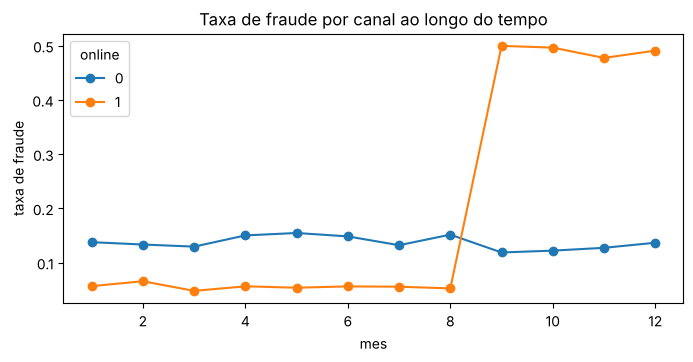

In [4]:
n = 24_000
mes = np.sort(rng.integers(1, 13, n))
online = rng.binomial(1, 0.5, n)
valor = rng.lognormal(4, 1, n)
peso_online = np.where(mes >= 9, 2.0, -1.0)
logit = -4 + 0.5 * np.log(valor) + peso_online * online + rng.normal(0, 0.5, n)
yt = rng.binomial(1, 1 / (1 + np.exp(-logit)))
Xt = pd.DataFrame({'online': online, 'valor': valor})

Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xt, yt, test_size=0.33, stratify=yt, random_state=0)
auc_aleat = roc_auc_score(ya_te, LogisticRegression().fit(Xa_tr, ya_tr).predict_proba(Xa_te)[:, 1])
tr, te = mes <= 8, mes >= 9
auc_oot = roc_auc_score(yt[te], LogisticRegression().fit(Xt[tr], yt[tr]).predict_proba(Xt[te])[:, 1])
print(f"AUC com split aleatório: {auc_aleat:.3f}")
print(f"AUC out of time:         {auc_oot:.3f}")

pd.DataFrame({'mes': mes, 'online': online, 'fraude': yt}).groupby(['mes', 'online'])['fraude'].mean().unstack().plot(
    title='Taxa de fraude por canal ao longo do tempo', marker='o'); plt.ylabel('taxa de fraude'); plt.show()

**Leitura:** o split aleatório mistura meses antigos e novos no treino e no teste, então esconde a mudança de padrão. O out of time mostra o que aconteceria de verdade: o modelo treinado no passado erra quando o golpe muda (*concept drift*). A AUC fica até abaixo de 0,5, porque a relação entre canal e fraude se inverteu: o modelo passa a apontar justamente o lado errado.

**Como evitar:** em dado temporal, validar sempre no futuro e monitorar o modelo depois de colocá-lo em uso.

## 4. Amostra pequena: o que um 100% realmente diz

Um modelo acertou 10 de 10 casos revisados por humano. Depois, com uma base maior, acertou 92 de 100 (92%). Qual resultado é mais confiável? O **intervalo de confiança** (Clopper-Pearson, 95%) responde.

,acerto,IC 95% inferior,IC 95% superior
resultado,,,
10 de 10,100.0%,69.2%,100.0%
92 de 100,92.0%,84.8%,96.5%
460 de 500,92.0%,89.3%,94.2%


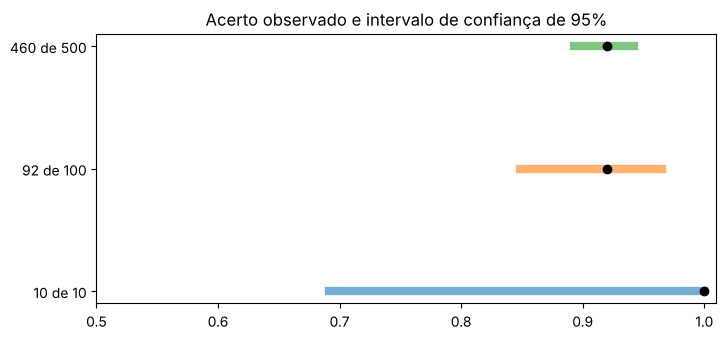

In [5]:
casos = [('10 de 10', 10, 10), ('92 de 100', 92, 100), ('460 de 500', 460, 500)]
linhas = []
for nome, k, n_ in casos:
    lo, hi = proportion_confint(k, n_, alpha=0.05, method='beta')
    linhas.append({'resultado': nome, 'acerto': k / n_, 'IC 95% inferior': lo, 'IC 95% superior': hi})
ic = pd.DataFrame(linhas).set_index('resultado')
display(ic.style.format('{:.1%}'))

fig, ax = plt.subplots()
for i, (nome, r) in enumerate(ic.iterrows()):
    ax.plot([r['IC 95% inferior'], r['IC 95% superior']], [i, i], lw=6, alpha=0.6)
    ax.plot(r['acerto'], i, 'ko')
ax.set_yticks(range(len(ic))); ax.set_yticklabels(ic.index); ax.set_xlim(0.5, 1.01)
ax.set_title('Acerto observado e intervalo de confiança de 95%'); plt.show()

**Leitura:** com 10 casos, o intervalo vai de cerca de 69% a 100%. Ou seja, o modelo poderia ser bem pior do que parece. Com 100 casos, os 92% vêm com um intervalo muito mais estreito, e com mais casos o intervalo fecha ainda mais.

**Como evitar:** sempre reportar o tamanho da amostra junto com a métrica e ampliar o gabarito antes de confiar em um número.

## Resumo

| Armadilha | Sinal de alerta | Prevenção |
|---|---|---|
| Variável do futuro | uma variável explica quase tudo | perguntar se o valor existe no momento da decisão |
| Pré-processamento antes do split | resultado bom em dado sem sinal | todo o preparo dentro de um `Pipeline` |
| Split aleatório em dado temporal | queda de desempenho em produção | validação out of time e monitoramento |
| Amostra pequena | 100% com poucos casos | intervalo de confiança e gabarito maior |